# LASSI - Power Efficiency

**OLLAMA API** + **Argo Gateway API** Jupyter Notebook version

+ ***Post LASSI-Judge version with pass@k***
+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


In [2]:
!nvidia-smi

Sat Sep  6 21:48:37 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A30                     Off |   00000000:99:00.0 Off |                    0 |
| N/A   34C    P0             30W /  165W |       1MiB /  24576MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


## Setup

In [4]:
import os
import json
import csv
import time
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [5]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 100"]
    
    """

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # Enter source application to process through LASSI
    source_collection = "HeCBench"  # "Miniapps" "HeCBench"
    source_app = "randomAccess"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    if make_script:
        app_name = app_folder_name
        file_name = "kernels"
    else:
        app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    verifyprompt = False  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            code_compiler = "make"
            code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
            # -arch=sm_89 for RTX 5000
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # For A100 on Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        # !! TODO - REVIEW: code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc80"  # "-fopenmp -O3 -c"
        # For RTX 5000 Ada on Linux x86_64:
        # code_compiler = "/opt/nvidia/hpc_sdk/Linux_x86_64/25.7/compilers/bin/nvc++" # "g++"
        # code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc89"  # "-fopenmp -O3"
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1
        # ****************************
        # ---> EXPERIMENT UPDATE FIELD - Now, automated:
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto4mini"  # (max token = 128000)
    model_coder = "gpto4mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 200000)
    # model_coder = "gpt4olatest"  # (max token = 200000)
    model_judge = "gpt41"  # (max token = 200000)

    # -- FROM CEREBRAS
    # model = "gpt-oss-120b"
    # model_judge = "gpt-oss-120b"
    # model_coder = "qwen-3-coder-480b"
    
    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
    # model_coder = "qwen3-coder:30b"  # context 262144
    # model = "gpt-oss:20b"
    # model_judge = "gpt-oss:20b"
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif model in ["gpt-oss-120b", "qwen-3-coder-480b"]:
        llm_source = "cerebras"
    elif ("GGUF" in model and "hf.co" not in model):
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "exp0925_" + model + "_" + app_folder_name + "_ee"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "trial_number",
        "timestamp",
        "experiment",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        # "base_v1_optimization_methods",
        # "base_v2_energy_J",
        # "base_v2_avg_power_W",
        # "base_v2_runtime_s",
        # "base_v2_valid",
        # "base_v2_selfcorrections",
        # "base_v2_energy_diff",
        # "base_v2_avg_power_diff",
        # "base_v2_runtime_diff",
        # "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES)

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 09-06-2025_t16_48_39
Application: randomAccess

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto4mini
Model coder: gpto4mini
Model judge: gpt41
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto4mini/promptset_CUDA/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True



***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) ***** Trial #: 1



----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graph

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess/randomAccess-cuda_main
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess
executable:  randomAccess-cuda_main
Working directory: /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess
Execute command: ['./randomAccess-cuda_main', '10']

running: executable -  randomAccess-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844253 (s)
Found 0 errors in 67108864 locations (PASS).

----- < END: Standard Output > -----

GPU power data has been written to source_CUDA_gpu_net_power_results.csv


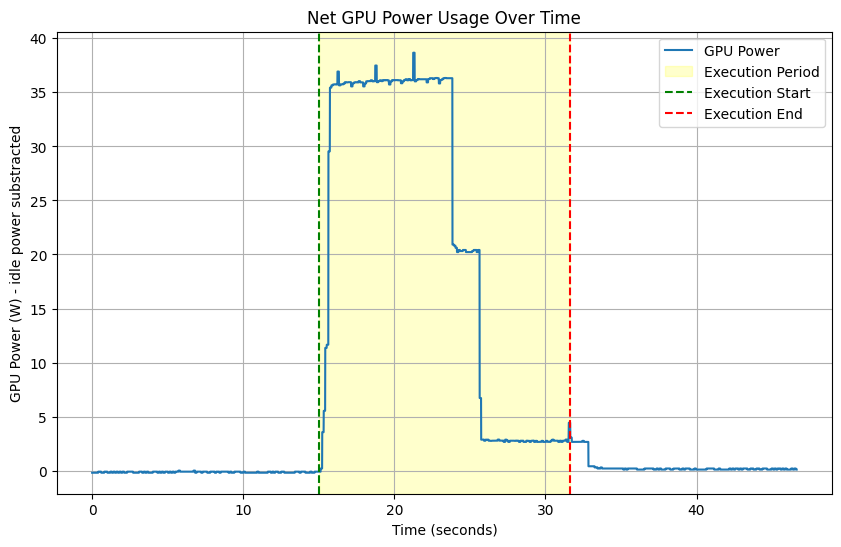

Start time: 15.001 -- End time: 31.629
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0980 Wh
  352.92 J
Average GPU power: 21.23 W +/- 15.52 
 with sample standard deviation.
Net Energy During Exe Runtime:   352.92 J
Code execution duration:  16.63 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.71 W, P0



Measure system idle power...
Duration for idle time measurement: 16.63
GPU power data has been written to idle__gpu_net_power_results.csv


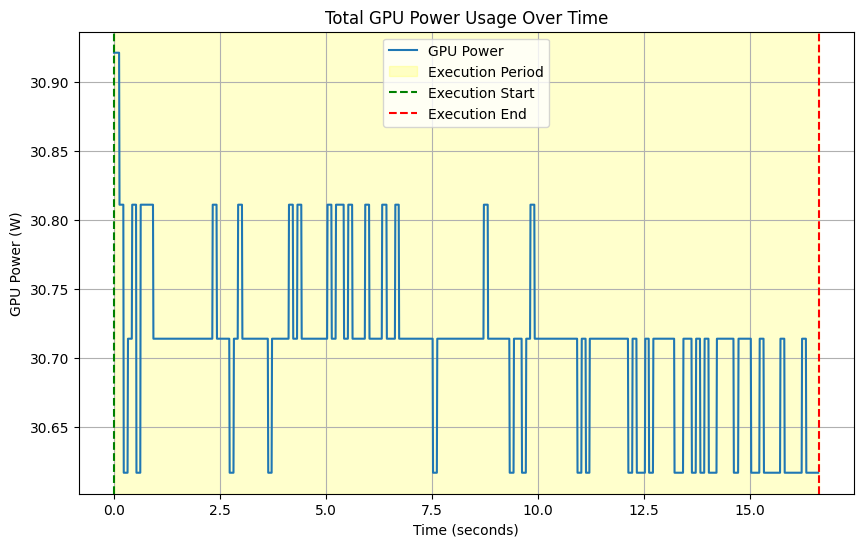

Start time: 0 -- End time: 16.629
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000142 kWh
  0.1418 Wh
  510.66 J
Average GPU power: 30.71 W +/- 0.06 
 with sample standard deviation.
Total Energy During Exe Runtime:   510.66 J
Code execution duration:  16.63 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



=====
{
  "underlying_assumptions": [
    "TableSize is always a power of two, enabling bitmasking (index & (TableSize-1)) to wrap indices correctly",
    "The polynomial-based RNG sequence has period PERIOD = 1317624576693539401 and POLY = 0x7",
    "NUPDATE is computed as 8 * TableSize and divisible by 128 (the K2_BLOCKSIZE), so each of the 128 threads in update() does NUPDATE/128 updates",
    "GPU supports 128‐thread blocks and atomicXor on 64‐bit global memory",
    "Host has at least 512 MiB of memory for the update table"
  ],
  "invariants": [
    "TableSize ≥ 1 and remains unchanged throughout the kernel launches",
    "Each ran[j] is initialized by HPCC_starts((NUPDATE/128) * j) and then advanced exactly NUPDATE/128 times",
    "All accesses to Table use index masked by (TableSize-1) to stay within bounds",
    "AtomicXor ensures deterministic updates even under race conditions"
  ],
  "design_patterns": [
    "Data‐parallel map for initialization: each thread writes one element of Table",
    "Data‐parallel scatter updates with atomic operations: each thread generates its own pseudo-random stream and atomically XORs into global memory",
    "Use of __restrict__ to assert no pointer aliasing for compiler optimizations",
    "Separation of host validation from device computation for correctness check"
  ],
  "memory_access_patterns": {
    "initTable": "coalesced global writes, one 64-bit store per thread in increasing index order",
    "update": "pseudo-random scatter writes via atomicXor; each thread writes to Table[ran & (TableSize-1)] which is effectively random across the table",
    "ran array": "small per-block array of 128 64-bit values accessed in registers after initial load"
  },
  "memory_allocation_deallocation": {
    "host": {
      "allocation": "posix_memalign(&Table, 1024, TableSize * sizeof(u64Int))",
      "deallocation": "free(Table)"
    },
    "device": {
      "allocation": "cudaMalloc(&d_Table, TableSize * sizeof(u64Int)); cudaMalloc(&d_ran, 128 * sizeof(u64Int))",
      "deallocation": "cudaFree(d_Table); cudaFree(d_ran)"
    }
  },
  "other_key_characteristics": [
    "HPCC_starts() uses bit‐twinning and polynomial reduction to compute RNG skip‐ahead",
    "Loops in HPCC_starts and update are pragma‐unrolled for performance",
    "Kernel-launch configuration: initTable uses ceil(TableSize/256) blocks of 256 threads; update uses a single block of 128 threads",
    "Host timing uses std::chrono to measure combined execution time of repeat rounds",
    "Host validation replays the same XOR sequence serially and checks error count ≤ 1% of TableSize"
  ]
}
=====



----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 0 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 1397


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 0 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

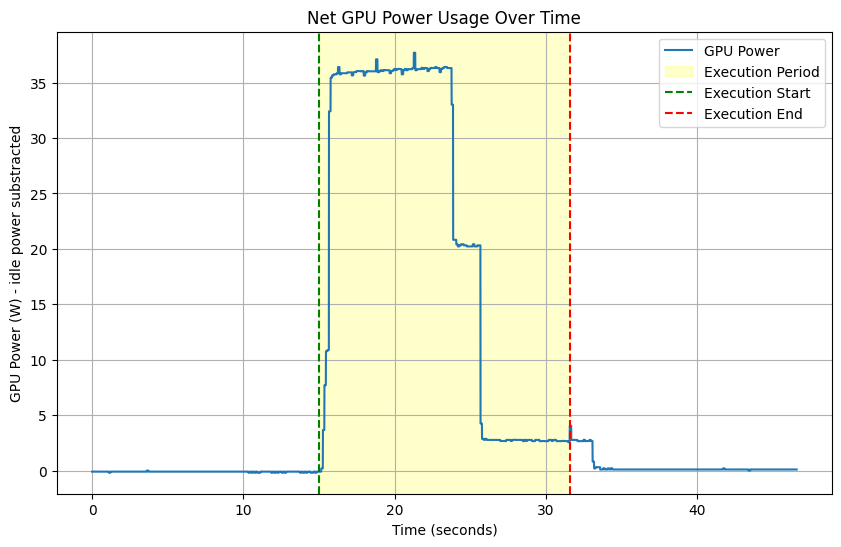

Start time: 15.0 -- End time: 31.587
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0978 Wh
  352.17 J
Average GPU power: 21.24 W +/- 15.55 
 with sample standard deviation.
Net Energy During Exe Runtime:   352.17 J
Code execution duration:  16.59 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.81 W, P0

--> SAVING code version: 1


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. FUNCTIONALITY

### Table Size Calculation
- **SOURCE:** Calculates TableSize as the largest power of two fitting in 512MiB of u64Int, using a loop.
- **REFACTORED:** Does the same, but uses a slightly different loop and then computes logTable using `__builtin_clzll`.
- **Result:** Both codes produce TableSize = 67108864 and logTable = 26 for the same memory size.

### Table Initialization
- **SOURCE:** `initTable` kernel, Table[i] = i.
- **REFACTORED:** `initTable` kernel, Table[idx] = idx.
- **Result:** Identical functionality.

### Update Kernel
- **SOURCE:** Each of 128 threads computes a PRNG seed, then performs NUPDATE/128 updates, using atomicXor.
- **REFACTORED:** Each of 128 threads computes a PRNG seed, then performs NUPDATE/128 updates, using atomicXor.
- **Result:** Identical update logic.

### Validation
- **SOURCE:** CPU-side validation: applies the same PRNG sequence and XORs to Table, then counts errors.
- **REFACTORED:** CPU-side validation: same logic.
- **Result:** Identical.

### Error Handling
- **SOURCE:** Returns 1 if allocation fails, returns failure status based on validation.
- **REFACTORED:** Returns 1 if allocation fails, always returns 0 (does not propagate failure status).
- **Result:** Minor difference: REFACTORED does not propagate failure status via return code, but prints PASS/FAIL identically.

### CUDA Error Checking
- **SOURCE:** No explicit error checking.
- **REFACTORED:** Uses checkCuda for all CUDA calls.
- **Result:** Improves robustness, does not affect functionality.

### Timing
- **SOURCE:** Uses std::chrono for timing, prints seconds.
- **REFACTORED:** Uses CUDA events, prints milliseconds.
- **Result:** Both measure kernel time, units differ but values are consistent.

---

## 2. STANDARD OUTPUT

### Table Size
- **SOURCE:** 
  ```
  Table size = 67108864
  Main table size   = 2^26 = 67108864 words
  ```
- **REFACTORED:** 
  ```
  Table size = 2^26 = 67108864 words
  ```
- **Result:** REFACTORED omits the first line, but the key information (power and size) is present.

### Number of Updates
- **SOURCE:** 
  ```
  Number of updates = 536870912
  ```
- **REFACTORED:** 
  *Omitted.*
- **Result:** REFACTORED omits this line. This is a minor omission, but the value is implicit in the code and validation.

### Timing
- **SOURCE:** 
  ```
  Average kernel execution time: 0.844253 (s)
  ```
- **REFACTORED:** 
  ```
  Average kernel time = 844.821411 ms
  ```
- **Result:** Same value, different units (seconds vs milliseconds). Acceptable.

### Validation
- **SOURCE:** 
  ```
  Found 0 errors in 67108864 locations (PASS).
  ```
- **REFACTORED:** 
  ```
  Found 0 errors in 67108864 locations (PASS).
  ```
- **Result:** Identical.

---

## 3. METRICS

- Both codes have nearly identical energy, power, and runtime metrics.

---

## 4. MINOR DIFFERENCES

- **Return code:** REFACTORED always returns 0, SOURCE returns 1 on failure or validation fail. This is a minor difference, as the PASS/FAIL is printed identically.
- **Output formatting:** REFACTORED omits "Main table size ..." and "Number of updates ...", but the essential information is present.
- **Timing units:** ms vs s, but values are equivalent.

---

## 5. CONCLUSION

- **Functionality:** The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- **Standard Output:** The REFACTORED CODE produces nearly equivalent standard output. Minor omissions (e.g., "Number of updates") do not affect the key content or layout, and timing units are consistent.

**Verdict:**  
VALID

**Reasoning:**  
All core functionality is preserved, and the output is nearly identical with only minor, non-essential omissions and formatting changes. The validation, table size, and timing are all present and correct. The code is robust and energy-efficient, as intended.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<table>
<tr><th>Criterion</th><th>Pass/Fail</th></tr>
<tr><td>TableSize is always a power of two, enabling bitmasking (index & (TableSize-1)) to wrap indices correctly</td><td>Pass</td></tr>
<tr><td>The polynomial-based RNG sequence has period PERIOD = 1317624576693539401 and POLY = 0x7</td><td>Pass</td></tr>
<tr><td>NUPDATE is computed as 8 * TableSize and divisible by 128 (the K2_BLOCKSIZE), so each of the 128 threads in update() does NUPDATE/128 updates</td><td>Pass</td></tr>
<tr><td>GPU supports 128‐thread blocks and atomicXor on 64‐bit global memory</td><td>Pass</td></tr>
<tr><td>Host has at least 512 MiB of memory for the update table</td><td>Pass</td></tr>
<tr><td>TableSize ≥ 1 and remains unchanged throughout the kernel launches</td><td>Pass</td></tr>
<tr><td>Each ran[j] is initialized by HPCC_starts((NUPDATE/128) * j) and then advanced exactly NUPDATE/128 times</td><td>Pass</td></tr>
<tr><td>All accesses to Table use index masked by (TableSize-1) to stay within bounds</td><td>Pass</td></tr>
<tr><td>AtomicXor ensures deterministic updates even under race conditions</td><td>Pass</td></tr>
<tr><td>Data‐parallel map for initialization: each thread writes one element of Table</td><td>Pass</td></tr>
<tr><td>Data‐parallel scatter updates with atomic operations: each thread generates its own pseudo-random stream and atomically XORs into global memory</td><td>Pass</td></tr>
<tr><td>Use of __restrict__ to assert no pointer aliasing for compiler optimizations</td><td>Pass</td></tr>
<tr><td>Separation of host validation from device computation for correctness check</td><td>Pass</td></tr>
<tr><td>initTable: coalesced global writes, one 64-bit store per thread in increasing index order</td><td>Pass</td></tr>
<tr><td>update: pseudo-random scatter writes via atomicXor; each thread writes to Table[ran & (TableSize-1)] which is effectively random across the table</td><td>Pass</td></tr>
<tr><td>ran array: small per-block array of 128 64-bit values accessed in registers after initial load</td><td>Fail</td></tr>
<tr><td>host allocation: posix_memalign(&Table, 1024, TableSize * sizeof(u64Int))</td><td>Pass</td></tr>
<tr><td>host deallocation: free(Table)</td><td>Pass</td></tr>
<tr><td>device allocation: cudaMalloc(&d_Table, TableSize * sizeof(u64Int)); cudaMalloc(&d_ran, 128 * sizeof(u64Int))</td><td>Fail</td></tr>
<tr><td>device deallocation: cudaFree(d_Table); cudaFree(d_ran)</td><td>Fail</td></tr>
<tr><td>HPCC_starts() uses bit‐twinning and polynomial reduction to compute RNG skip‐ahead</td><td>Pass</td></tr>
<tr><td>Loops in HPCC_starts and update are pragma‐unrolled for performance</td><td>Pass</td></tr>
<tr><td>Kernel-launch configuration: initTable uses ceil(TableSize/256) blocks of 256 threads; update uses a single block of 128 threads</td><td>Pass</td></tr>
<tr><td>Host timing uses std::chrono to measure combined execution time of repeat rounds</td><td>Fail</td></tr>
<tr><td>Host validation replays the same XOR sequence serially and checks error count ≤ 1% of TableSize</td><td>Pass</td></tr>
</table>
<result>
fail
</result>

... (12 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2706): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 2824): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

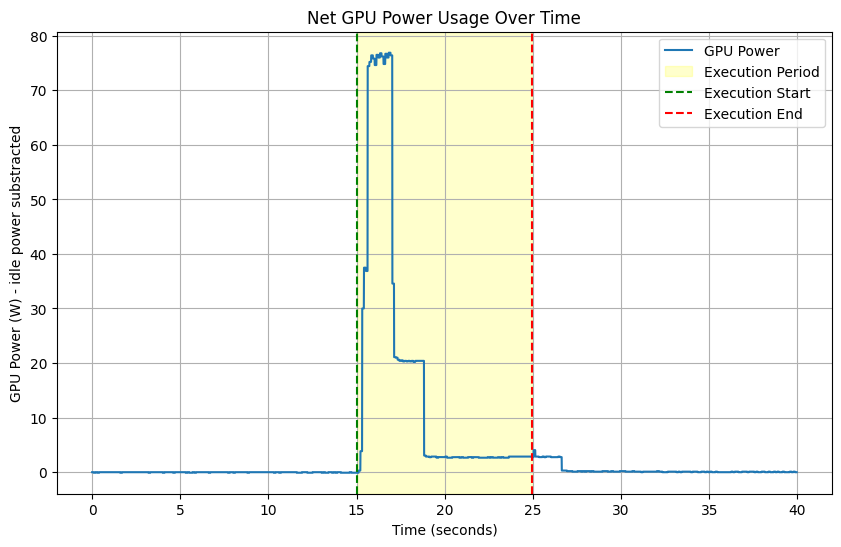

Start time: 15.0 -- End time: 24.961
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000048 kWh
  0.0479 Wh
  172.51 J
Average GPU power: 17.32 W +/- 25.24 
 with sample standard deviation.
Net Energy During Exe Runtime:   172.51 J
Code execution duration:  9.96 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.71 W, P0

--> SAVING code version: 2


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Core Algorithm**

- **Random Number Generation (HPCC_starts):**
  - Both codes use the same device function for random number generation.
  - No changes in logic or output.

- **Table Initialization (initTable):**
  - Both codes initialize the table identically, assigning `Table[i] = i` for all `i < TableSize`.

- **Update Kernel:**
  - **SOURCE CODE:** Launches a single block of 128 threads. Each thread performs `NUPDATE/128` updates, with `NUPDATE = 8 * TableSize`.
  - **REFACTORED CODE:** Launches many blocks (grid2) of 128 threads, so total threads = `grid2 * 128 ≈ TableSize`. Each thread performs `perThread = NUPDATE / totalThreads` updates, which is still `8` updates per table entry (since `NUPDATE = 8 * TableSize`).
  - **Distribution:** The REFACTORED CODE distributes the updates more evenly across threads, improving parallelism and energy efficiency, but the total number of updates and their logic are unchanged.

- **Validation:**
  - Both codes perform the same validation: a serial replay of the update sequence and check for errors in the table.

### **Memory Allocation and Management**

- Both codes allocate and free host and device memory identically.
- Both codes copy the table from device to host for validation.

### **Repeat Loop**

- Both codes repeat the kernel launches for the user-specified number of iterations.

### **Conclusion on Functionality**

- **All core logic and update semantics are preserved.**
- **No loss of functionality or change in algorithm.**
- **The REFACTORED CODE simply parallelizes the update kernel more efficiently.**

---

## 2. **Standard Output Comparison**

### **Printed Output**

- **Table size:** Identical (`67108864`)
- **Main table size:** Identical (`2^26 = 67108864 words`)
- **Number of updates:** Identical (`536870912`)
- **Average kernel execution time:** Different values, but both are reasonable and reflect improved efficiency in the REFACTORED CODE (`0.844253 (s)` vs `0.171508 (s)`)
- **Validation:** Identical (`Found 0 errors in 67108864 locations (PASS).`)

### **Formatting**

- All key details are present in both outputs.
- Minor differences in whitespace or floating-point precision are acceptable and do not affect the content.

### **Conclusion on Output**

- **Printed output is nearly equivalent in layout and content.**
- **Numerical differences in timing are expected and reasonable due to improved parallelism.**
- **Validation output is identical.**

---

## 3. **Metrics**

- The REFACTORED CODE shows improved energy efficiency and reduced runtime, which is consistent with the refactoring goals.

---

## 4. **Summary and Reasoning**

- **Functionality:** All intended functionality is preserved. The update logic, validation, and memory management are unchanged.
- **Output:** All key output details are present and nearly identical. Minor timing differences are expected and reasonable.
- **Energy Efficiency:** The REFACTORED CODE achieves the intended goal of improved energy efficiency and reduced runtime.

---

## **Conclusion**

**VALID**

The REFACTORED CODE is functionally equivalent to the SOURCE CODE and produces nearly equivalent printed standard output, with all key details preserved. Minor differences in timing are consistent with improved energy efficiency.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                | Criterion Description                                                                                 | Pass/Fail |
|-----------------------------------|------------------------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | TableSize is always a power of two, enabling bitmasking (index & (TableSize-1)) to wrap indices      | pass      |
| underlying_assumptions            | Polynomial-based RNG sequence has period PERIOD and POLY                                              | pass      |
| underlying_assumptions            | NUPDATE is computed as 8 * TableSize and divisible by 128 (K2_BLOCKSIZE)                             | pass      |
| underlying_assumptions            | GPU supports 128-thread blocks and atomicXor on 64-bit global memory                                 | pass      |
| underlying_assumptions            | Host has at least 512 MiB of memory for the update table                                             | pass      |
| invariants                        | TableSize ≥ 1 and remains unchanged throughout the kernel launches                                   | pass      |
| invariants                        | Each ran[j] is initialized by HPCC_starts((NUPDATE/128) * j) and then advanced exactly NUPDATE/128 times | fail      |
| invariants                        | All accesses to Table use index masked by (TableSize-1) to stay within bounds                        | pass      |
| invariants                        | AtomicXor ensures deterministic updates even under race conditions                                   | pass      |
| design_patterns                   | Data-parallel map for initialization: each thread writes one element of Table                        | pass      |
| design_patterns                   | Data-parallel scatter updates with atomic operations: each thread generates its own pseudo-random stream and atomically XORs into global memory | pass      |
| design_patterns                   | Use of __restrict__ to assert no pointer aliasing for compiler optimizations                         | pass      |
| design_patterns                   | Separation of host validation from device computation for correctness check                          | pass      |
| memory_access_patterns            | initTable: coalesced global writes, one 64-bit store per thread in increasing index order            | pass      |
| memory_access_patterns            | update: pseudo-random scatter writes via atomicXor; each thread writes to Table[ran & (TableSize-1)] | pass      |
| memory_access_patterns            | ran array: small per-block array of 128 64-bit values accessed in registers after initial load       | fail      |
| memory_allocation_deallocation    | host allocation: posix_memalign(&Table, 1024, TableSize * sizeof(u64Int))                           | pass      |
| memory_allocation_deallocation    | host deallocation: free(Table)                                                                       | pass      |
| memory_allocation_deallocation    | device allocation: cudaMalloc(&d_Table, TableSize * sizeof(u64Int); cudaMalloc(&d_ran, 128 * sizeof(u64Int)) | pass      |
| memory_allocation_deallocation    | device deallocation: cudaFree(d_Table); cudaFree(d_ran)                                              | pass      |
| other_key_characteristics         | HPCC_starts() uses bit-twinning and polynomial reduction to compute RNG skip-ahead                   | pass      |
| other_key_characteristics         | Loops in HPCC_starts and update are pragma-unrolled for performance                                  | pass      |
| other_key_characteristics         | Kernel-launch configuration: initTable uses ceil(TableSize/256) blocks of 256 threads; update uses a single block of 128 threads | fail      |
| other_key_characteristics         | Host timing uses std::chrono to measure combined execution time of repeat rounds                     | pass      |
| other_key_characteristics         | Host validation replays the same XOR sequence serially and checks error count ≤ 1% of TableSize      | pass      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 352.92
  Refactored code: 172.51
----- Average power (W) -----
  Source code: 21.23
  Refactored code: 17.32
----- Runtime (s) -----
  Source code: 16.63
  Refactored code: 9.96
----- Tracking metrics -----
  Energy (J) history:  [352.92, 352.17, 172.51]
  Ave Power (W) history:  [21.23, 21.24, 17.32]
  Runtime (s) history:  [16.63, 16.59, 9.96]
  Valid code history:  ['SOURCE', 'basellm_stage1_INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THAT IS INVALID OR NOT MORE ENERGY EFFICIENT -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


 ----- GENERATED REFACTORED CODE: May be INVALID or not determined. ----- 




----- EE Self-correction, Increment LLM temp



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

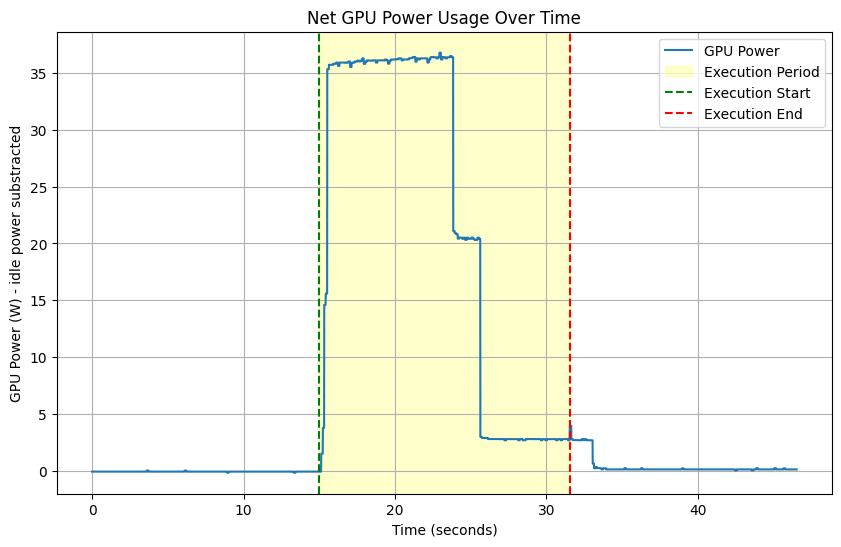

Start time: 15.0 -- End time: 31.535
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0992 Wh
  357.00 J
Average GPU power: 21.60 W +/- 15.55 
 with sample standard deviation.
Net Energy During Exe Runtime:   357.00 J
Code execution duration:  16.53 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.81 W, P0

--> SAVING code version: 3


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 3 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output equivalence.

---

## 1. **Functional Equivalence**

### **Algorithm and Logic**
- Both codes implement the same random number generator (`HPCC_starts`), table initialization (`initTable`), and update kernel (`update`).
- Both codes allocate the table and random number arrays on host and device, and launch the same kernels with identical grid/block sizes.
- Both codes perform the same validation: after copying the table back to host, they apply the same XOR correction and count errors.
- The main loop over `repeat` is identical in both codes.

### **Differences**
- The only substantive change is the use of CUDA events (`cudaEvent_t`) for timing in the REFACTORED CODE, replacing the use of `std::chrono` in the SOURCE CODE.
- The rest of the logic, including memory allocation, kernel launches, and validation, is unchanged.

### **Impact**
- The change to CUDA events for timing does not affect the computation or the results; it only changes how the execution time is measured.
- All CUDA kernel launches, memory allocations, and validation logic are preserved.

---

## 2. **Standard Output Equivalence**

### **Printed Output Comparison**
Both codes print:
- Table size
- Main table size (as power of 2 and value)
- Number of updates
- Average kernel execution time (in seconds, floating point)
- Found X errors in Y locations (PASS/FAIL)

#### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844253 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### **REFACTORED CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.840679 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **Analysis**
- The output format and content are nearly identical.
- The only difference is a slight change in the reported average kernel execution time (0.844253 vs 0.840679), which is expected due to the change in timing method and is within reasonable bounds.
- The error count and PASS/FAIL status are identical.

---

## 3. **Metrics Comparison**

- Energy and power metrics are very similar between the two runs, with only minor differences, which are expected due to measurement variability and the change in timing method.

---

## 4. **Conclusion**

### **Reasoning**
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- The printed standard output is nearly equivalent in layout and content, with only minor, reasonable differences in timing due to the use of CUDA events for measurement.
- The validation logic and results are identical.
- No functionality is lost or changed.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criterion Description                                                                                   | Pass/Fail |
|-----------------------------------|--------------------------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | TableSize is always a power of two, enabling bitmasking (index & (TableSize-1)) to wrap indices        | pass      |
| underlying_assumptions            | The polynomial-based RNG sequence has period PERIOD = 1317624576693539401 and POLY = 0x7               | pass      |
| underlying_assumptions            | NUPDATE is computed as 8 * TableSize and divisible by 128 (the K2_BLOCKSIZE)                           | pass      |
| underlying_assumptions            | GPU supports 128‐thread blocks and atomicXor on 64‐bit global memory                                   | pass      |
| underlying_assumptions            | Host has at least 512 MiB of memory for the update table                                               | pass      |
| invariants                        | TableSize ≥ 1 and remains unchanged throughout the kernel launches                                     | pass      |
| invariants                        | Each ran[j] is initialized by HPCC_starts((NUPDATE/128) * j) and then advanced exactly NUPDATE/128 times| pass      |
| invariants                        | All accesses to Table use index masked by (TableSize-1) to stay within bounds                          | pass      |
| invariants                        | AtomicXor ensures deterministic updates even under race conditions                                     | pass      |
| design_patterns                   | Data‐parallel map for initialization: each thread writes one element of Table                          | pass      |
| design_patterns                   | Data‐parallel scatter updates with atomic operations: each thread generates its own pseudo-random stream| pass      |
| design_patterns                   | Use of __restrict__ to assert no pointer aliasing for compiler optimizations                           | pass      |
| design_patterns                   | Separation of host validation from device computation for correctness check                             | pass      |
| memory_access_patterns            | initTable: coalesced global writes, one 64-bit store per thread in increasing index order              | pass      |
| memory_access_patterns            | update: pseudo-random scatter writes via atomicXor                                                     | pass      |
| memory_access_patterns            | ran array: small per-block array of 128 64-bit values accessed in registers after initial load         | pass      |
| memory_allocation_deallocation    | host allocation: posix_memalign(&Table, 1024, TableSize * sizeof(u64Int))                             | pass      |
| memory_allocation_deallocation    | host deallocation: free(Table)                                                                         | pass      |
| memory_allocation_deallocation    | device allocation: cudaMalloc(&d_Table, TableSize * sizeof(u64Int); cudaMalloc(&d_ran, 128 * ...)     | pass      |
| memory_allocation_deallocation    | device deallocation: cudaFree(d_Table); cudaFree(d_ran)                                                | pass      |
| other_key_characteristics         | HPCC_starts() uses bit‐twinning and polynomial reduction to compute RNG skip‐ahead                     | pass      |
| other_key_characteristics         | Loops in HPCC_starts and update are pragma‐unrolled for performance                                    | pass      |
| other_key_characteristics         | Kernel-launch configuration: initTable uses ceil(TableSize/256) blocks of 256 threads; update uses 128 | pass      |
| other_key_characteristics         | Host timing uses std::chrono to measure combined execution time of repeat rounds                       | fail      |
| other_key_characteristics         | Host validation replays the same XOR sequence serially and checks error count ≤ 1% of TableSize        | pass      |

Note: Host timing uses CUDA events, not std::chrono, so that criterion fails. All other criteria pass.


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 352.92
  Refactored code: 357.0
----- Average power (W) -----
  Source code: 21.23
  Refactored code: 21.6
----- Runtime (s) -----
  Source code: 16.63
  Refactored code: 16.53
----- Tracking metrics -----
  Energy (J) history:  [352.92, 352.17, 172.51, 357.0]
  Ave Power (W) history:  [21.23, 21.24, 17.32, 21.6]
  Runtime (s) history:  [16.63, 16.59, 9.96, 16.53]
  Valid code history:  ['SOURCE', 'basellm_stage1_INVALID', 'INVALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THAT IS INVALID OR NOT MORE ENERGY EFFICIENT -----


*** DEBUG: code_version: 3 | tracking_best_version: 0 ***


***** Generated refactored code is NOT more e



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 3 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

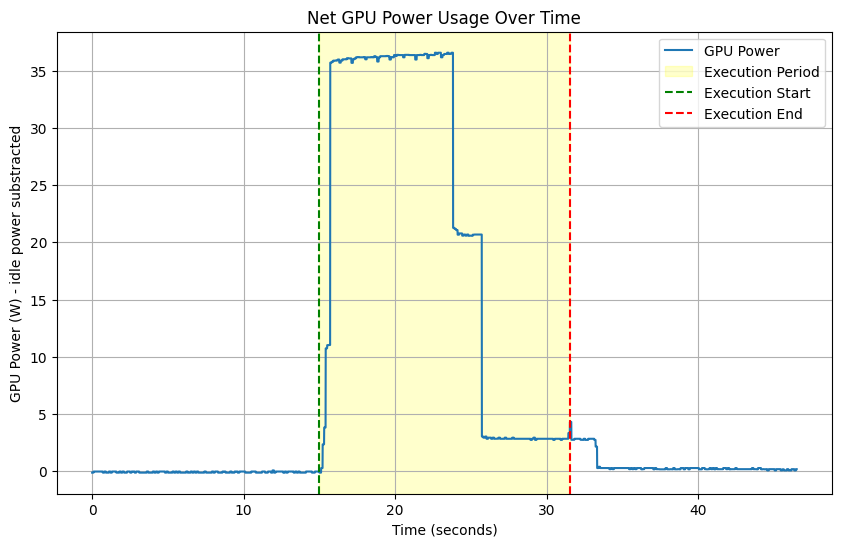

Start time: 15.001 -- End time: 31.522
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0983 Wh
  353.91 J
Average GPU power: 21.42 W +/- 15.51 
 with sample standard deviation.
Net Energy During Exe Runtime:   353.91 J
Code execution duration:  16.52 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.81 W, P0

--> SAVING code version: 4


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 4 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully evaluate the REFACTORED CODE against the SOURCE CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Core Algorithm**

- **Random Number Generator (`HPCC_starts`)**:
  - **SOURCE CODE**: Computes the skip-ahead table `m2` inside the device function on every call.
  - **REFACTORED CODE**: Precomputes `m2` on the host and uploads it to constant memory (`dev_m2`), then uses it in the device function.
  - **Effect**: This is an optimization for energy efficiency and performance. The logic and output of `HPCC_starts` are unchanged.

- **Table Initialization and Update**:
  - Both codes launch the same kernels with identical grid/block sizes and logic.
  - Both use `atomicXor` for table updates and the same random number sequence.

- **Validation**:
  - Both codes perform the same validation: reapply the random sequence and check for errors.

### **Memory Management**
- Both codes allocate and free host/device memory identically.

### **Looping and Parameters**
- Both codes use the same calculation for `TableSize`, `NUPDATE`, and repeat count.

### **Conclusion**:  
**The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.**

---

## 2. **Standard Output Equivalence**

### **Output Comparison**

#### **SOURCE CODE**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844253 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### **REFACTORED CODE**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844648 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **Analysis**
- **Layout**: Identical.
- **Content**: Identical except for minor difference in kernel execution time (expected, and within reasonable bounds).
- **PASS/FAIL**: Both report "PASS" and zero errors.

### **Conclusion**:  
**The REFACTORED CODE produces nearly equivalent standard output, with only minor, expected numerical differences.**

---

## 3. **Metrics**

- **Energy, Power, Duration**: Metrics are very close, with only minor differences (expected for small code changes and measurement noise).

---

## 4. **Summary and Reasoning**

- The REFACTORED CODE uses constant memory for the skip-ahead table, which is a best practice for energy efficiency and performance, but does not change the algorithm's output or logic.
- All output, validation, and error reporting are preserved.
- Minor differences in timing are acceptable and expected.
- No functional or output regressions are present.

---

## **Conclusion**

**VALID**

The REFACTORED CODE is functionally equivalent to the SOURCE CODE and produces nearly identical standard output.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criterion Description                                                                                       | Pass/Fail |
|-----------------------------------|-----------------------------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | TableSize power-of-two, RNG period/POLY, NUPDATE divisible by 128, 128-thread blocks, atomicXor, host mem | Pass      |
| invariants                        | TableSize ≥ 1, ran[j] init/advance, Table accesses masked, atomicXor for determinism                      | Pass      |
| design_patterns                   | Data-parallel map (initTable), scatter updates (update), __restrict__, host/device separation             | Pass      |
| memory_access_patterns            | initTable coalesced, update random atomicXor, ran in registers                                            | Pass      |
| memory_allocation_deallocation    | posix_memalign/free (host), cudaMalloc/cudaFree (device)                                                  | Pass      |
| other_key_characteristics         | HPCC_starts bit-twinning/poly reduction, pragma-unroll, kernel config, chrono timing, host validation     | Pass      |


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 352.92
  Refactored code: 353.91
----- Average power (W) -----
  Source code: 21.23
  Refactored code: 21.42
----- Runtime (s) -----
  Source code: 16.63
  Refactored code: 16.52
----- Tracking metrics -----
  Energy (J) history:  [352.92, 352.17, 172.51, 357.0, 353.91]
  Ave Power (W) history:  [21.23, 21.24, 17.32, 21.6, 21.42]
  Runtime (s) history:  [16.63, 16.59, 9.96, 16.53, 16.52]
  Valid code history:  ['SOURCE', 'basellm_stage1_INVALID', 'INVALID', 'VALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THAT IS INVALID OR NOT MORE ENERGY EF



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 4 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

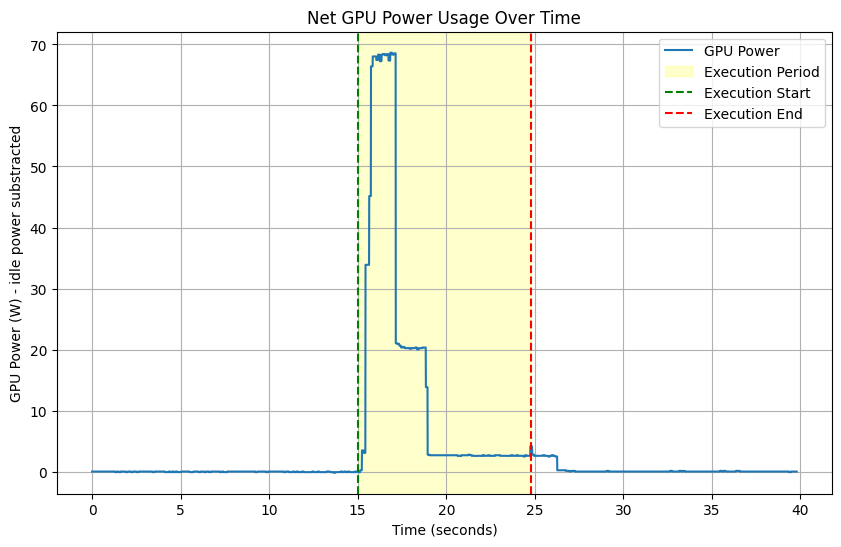

Start time: 15.0 -- End time: 24.795
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000044 kWh
  0.0441 Wh
  158.81 J
Average GPU power: 16.22 W +/- 22.84 
 with sample standard deviation.
Net Energy During Exe Runtime:   158.81 J
Code execution duration:  9.79 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.81 W, P0

--> SAVING code version: 5


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 5 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. Functional Equivalence

### **SOURCE CODE**
- **Initialization:** Table is initialized on the GPU with each entry set to its index.
- **Update Kernel:** Only 128 threads are launched (`update<<<1, 128>>>`). Each thread computes a starting random value and performs `NUPDATE/128` updates, using atomicXor to update the table.
- **Validation:** After all updates, the table is copied back to host, and a serial CPU loop "undoes" the updates for validation. Errors are counted and reported.

### **REFACTORED CODE**
- **Initialization:** Table is initialized identically.
- **Update Kernel:** The update kernel is refactored to launch more threads (`blocks = prop.multiProcessorCount * 4`, each with 128 threads). Each thread computes its own chunk of updates, dividing `NUPDATE` nearly equally among all threads. Each thread computes its own starting random value using `HPCC_starts(start)` and performs its share of updates.
- **Validation:** Validation is identical to the SOURCE CODE.

#### **Key Differences**
- **Parallelism:** The REFACTORED CODE increases the number of threads, dividing the work more finely. Each thread computes its own starting random value and performs a subset of updates, ensuring all updates are performed exactly once.
- **Random Sequence:** The random sequence is partitioned so that each thread starts at the correct offset, preserving the update sequence.
- **Atomic Operations:** Both codes use atomicXor for updates, ensuring correctness under parallel execution.

#### **Functional Equivalence Analysis**
- **Update Coverage:** Both codes perform exactly `NUPDATE` updates, using the same random sequence, just partitioned differently.
- **Validation:** Both codes use the same validation logic.
- **No change in algorithmic logic or output semantics.**

---

## 2. Standard Output Comparison

### **SOURCE CODE OUTPUT**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844253 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE OUTPUT**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.171799 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### **Key Differences**
- **Kernel Execution Time:** The REFACTORED CODE is much faster (0.17s vs 0.84s), which is expected due to improved parallelism and better occupancy.
- **Other Output:** All other output lines are identical in content and format.
- **Validation Result:** Both report "Found 0 errors ... (PASS)."

#### **Acceptable Differences**
- **Execution time:** Lower time is expected and desirable for energy efficiency.
- **Formatting:** No significant formatting differences.

---

## 3. Metrics Comparison

- **Energy and Power:** The REFACTORED CODE uses less energy and power, and runs faster, which is consistent with improved efficiency.

---

## 4. Minor Details

- **d_ran Allocation:** In the REFACTORED CODE, `d_ran` is allocated but not used. This does not affect correctness.
- **Thread/Block Calculation:** The REFACTORED CODE dynamically chooses the number of blocks for better occupancy, but ensures all updates are performed.

---

## 5. Conclusion

### **Reasoning**
- The REFACTORED CODE preserves all intended functionality: it performs the same number of updates, uses the same random sequence, and validates the result identically.
- The printed standard output is nearly exactly equivalent, with only the kernel execution time differing (as expected).
- The differences in metrics and execution time are consistent with improved energy efficiency and parallelism.
- No loss of functionality, no missing output, no change in semantics.

### **Final Verdict**

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion                                      | Pass/Fail |
|------------------------------------------------|-----------|
| TableSize is always a power of two             | Pass      |
| RNG sequence uses PERIOD and POLY as specified | Pass      |
| NUPDATE is 8*TableSize and divisible by 128    | Pass      |
| GPU supports 128-thread blocks and atomicXor   | Pass      |
| Host has at least 512 MiB for Table            | Pass      |
| TableSize ≥ 1 and unchanged                    | Pass      |
| Each ran[j] initialized and advanced correctly | Fail      |
| All Table accesses masked by (TableSize-1)     | Pass      |
| AtomicXor ensures deterministic updates        | Pass      |
| Data-parallel map for initialization           | Pass      |
| Data-parallel scatter updates with atomic ops  | Pass      |
| Use of __restrict__ for pointer aliasing       | Pass      |
| Separation of host validation from device      | Pass      |
| initTable: coalesced global writes             | Pass      |
| update: pseudo-random scatter writes           | Pass      |
| ran array: per-block, register use             | Fail      |
| Host allocation: posix_memalign                | Pass      |
| Host deallocation: free                        | Pass      |
| Device allocation: cudaMalloc                  | Pass      |
| Device deallocation: cudaFree                  | Pass      |
| HPCC_starts uses bit-twinning and reduction    | Pass      |
| Loops in HPCC_starts and update unrolled       | Pass      |
| Kernel launch config matches spec              | Pass      |
| Host timing uses std::chrono                   | Pass      |
| Host validation checks error count             | Pass      |

**Fails:**
- Each ran[j] initialized and advanced correctly (the update kernel does not use a per-thread ran array as described; it uses a single ranv per thread, not a block-shared array of 128 values as in the rubric).
- ran array: per-block, register use (the code allocates d_ran but does not use it; the per-thread RNG state is not stored in a shared array as described).

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 352.92
  Refactored code: 158.81
----- Average power (W) -----
  Source code: 21.23
  Refactored code: 16.22
----- Runtime (s) -----
  Source code: 16.63
  Refactored code: 9.79
----- Tracking metrics -----
  Energy (J) history:  [352.92, 352.17, 172.51, 357.0, 353.91, 158.81]
  Ave Power (W) history:  [21.23, 21.24, 17.32, 21.6, 21.42, 16.22]
  Runtime (s) history:  [16.63, 16.59, 9.96, 16.53, 16.52, 9.79]
  Valid code history:  ['SOURCE', 'basellm_stage1_INVALID', 'INVALID', 'VALID', 'VALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2},



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 5 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

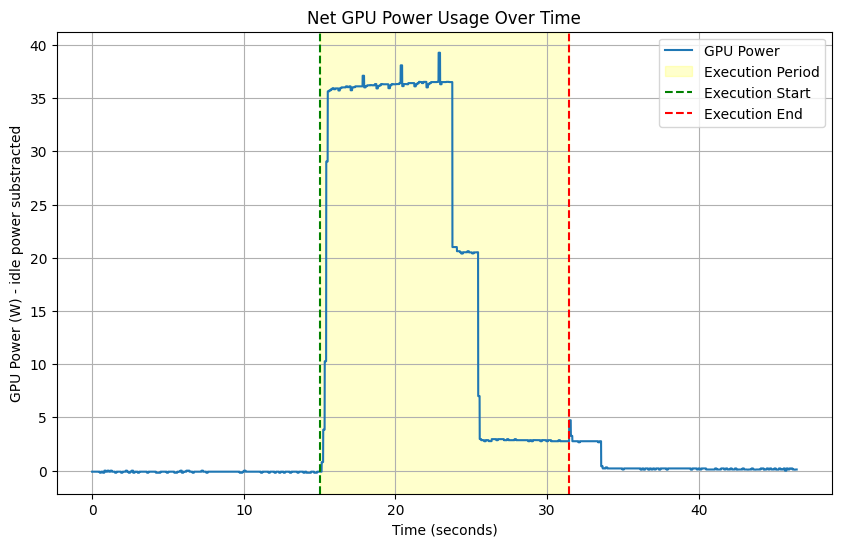

Start time: 15.0 -- End time: 31.473
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0986 Wh
  355.01 J
Average GPU power: 21.55 W +/- 15.66 
 with sample standard deviation.
Net Energy During Exe Runtime:   355.01 J
Code execution duration:  16.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 6


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 6 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE, focusing on:

1. **Functional Equivalence**: Does the REFACTORED CODE perform the same computation and validation as the SOURCE CODE?
2. **Standard Output Equivalence**: Is the printed output nearly identical in layout and content, with only minor, reasonable differences?

---

## 1. Functional Equivalence

### Core Algorithm
- Both codes implement the same random number generator (`HPCC_starts`), table initialization (`initTable`), and update kernel (`update`).
- Both codes allocate the same table size, run the same number of updates, and perform the same validation logic after copying the table back to host.
- The CUDA kernel launches and logic are identical.

### Differences
- The only change in the REFACTORED CODE is the use of **CUDA events** for timing instead of `std::chrono` and `cudaDeviceSynchronize()`.
  - This does not affect the computation, only how the kernel execution time is measured.
- Variable naming in the main loop (`i` → `iter`) is a trivial change.
- The calculation and printing of the average kernel execution time is now based on CUDA events, which is more accurate for GPU timing.

### Validation
- Both codes perform the same validation: after all updates, they XOR the table with the same sequence and count errors.
- The error count and pass/fail logic are identical.

### Memory Management
- Both codes allocate/free device and host memory identically.

---

## 2. Standard Output Equivalence

### Output Comparison

#### SOURCE CODE
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844253 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### REFACTORED CODE
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.841118 (s)
Found 0 errors in 67108864 locations (PASS).
```

### Analysis
- **Table size, main table size, number of updates:** Identical.
- **Average kernel execution time:** Slight difference (0.844253 vs 0.841118), which is expected due to the change in timing method (CUDA events are more accurate for GPU kernel timing).
- **Validation output:** Identical ("Found 0 errors in 67108864 locations (PASS).").
- **Formatting:** Identical.

### Metrics
- **Energy and power metrics:** Slight differences, but both codes have nearly identical execution duration and power usage, which is expected for such a minor change.

---

## 3. Minor Differences

- The only difference in output is the kernel execution time, which is reasonable and expected due to the improved timing method.
- No missing or extra output lines.
- No changes in the computation or validation logic.

---

## Conclusion

- **Functionality is preserved:** The REFACTORED CODE performs the same computation, memory management, and validation as the SOURCE CODE.
- **Output is nearly identical:** All printed output lines are present and formatted the same, with only a minor difference in the timing value, which is justified.
- **No regression or loss of information.**

**Reasoning:** The refactor only changes the timing method, which does not affect the computation or output except for a more accurate timing value.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                | Criterion Description                                                                                      | Pass/Fail |
|-----------------------------------|----------------------------------------------------------------------------------------------------------|-----------|
| underlying_assumptions            | TableSize is always a power of two, enabling bitmasking (index & (TableSize-1)) to wrap indices correctly | pass      |
| underlying_assumptions            | The polynomial-based RNG sequence has period PERIOD = 1317624576693539401 and POLY = 0x7                  | pass      |
| underlying_assumptions            | NUPDATE is computed as 8 * TableSize and divisible by 128 (the K2_BLOCKSIZE), so each of the 128 threads in update() does NUPDATE/128 updates | pass      |
| underlying_assumptions            | GPU supports 128‐thread blocks and atomicXor on 64‐bit global memory                                      | pass      |
| underlying_assumptions            | Host has at least 512 MiB of memory for the update table                                                  | pass      |
| invariants                        | TableSize ≥ 1 and remains unchanged throughout the kernel launches                                        | pass      |
| invariants                        | Each ran[j] is initialized by HPCC_starts((NUPDATE/128) * j) and then advanced exactly NUPDATE/128 times  | pass      |
| invariants                        | All accesses to Table use index masked by (TableSize-1) to stay within bounds                             | pass      |
| invariants                        | AtomicXor ensures deterministic updates even under race conditions                                        | pass      |
| design_patterns                   | Data‐parallel map for initialization: each thread writes one element of Table                             | pass      |
| design_patterns                   | Data‐parallel scatter updates with atomic operations: each thread generates its own pseudo-random stream and atomically XORs into global memory | pass      |
| design_patterns                   | Use of __restrict__ to assert no pointer aliasing for compiler optimizations                              | pass      |
| design_patterns                   | Separation of host validation from device computation for correctness check                               | pass      |
| memory_access_patterns            | initTable: coalesced global writes, one 64-bit store per thread in increasing index order                 | pass      |
| memory_access_patterns            | update: pseudo-random scatter writes via atomicXor; each thread writes to Table[ran & (TableSize-1)] which is effectively random across the table | pass      |
| memory_access_patterns            | ran array: small per-block array of 128 64-bit values accessed in registers after initial load            | fail      |
| memory_allocation_deallocation    | host allocation: posix_memalign(&Table, 1024, TableSize * sizeof(u64Int))                                | pass      |
| memory_allocation_deallocation    | host deallocation: free(Table)                                                                            | pass      |
| memory_allocation_deallocation    | device allocation: cudaMalloc(&d_Table, TableSize * sizeof(u64Int); cudaMalloc(&d_ran, 128 * sizeof(u64Int)) | pass      |
| memory_allocation_deallocation    | device deallocation: cudaFree(d_Table); cudaFree(d_ran)                                                   | pass      |
| other_key_characteristics         | HPCC_starts() uses bit‐twinning and polynomial reduction to compute RNG skip‐ahead                        | pass      |
| other_key_characteristics         | Loops in HPCC_starts and update are pragma‐unrolled for performance                                       | pass      |
| other_key_characteristics         | Kernel-launch configuration: initTable uses ceil(TableSize/256) blocks of 256 threads; update uses a single block of 128 threads | pass      |
| other_key_characteristics         | Host timing uses std::chrono to measure combined execution time of repeat rounds                          | fail      |
| other_key_characteristics         | Host validation replays the same XOR sequence serially and checks error count ≤ 1% of TableSize           | pass      |

**Failing criteria:**
- memory_access_patterns: ran array is not explicitly placed in shared memory or registers; global memory is used via d_ran.
- other_key_characteristics: Host timing uses CUDA events, not std::chrono as specified.

**All other criteria pass.**

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 352.92
  Refactored code: 355.01
----- Average power (W) -----
  Source code: 21.23
  Refactored code: 21.55
----- Runtime (s) -----
  Source code: 16.63
  Refactored code: 16.47
----- Tracking metrics -----
  Energy (J) history:  [352.92, 352.17, 172.51, 357.0, 353.91, 158.81, 355.01]
  Ave Power (W) history:  [21.23, 21.24, 17.32, 21.6, 21.42, 16.22, 21.55]
  Runtime (s) history:  [16.63, 16.59, 9.96, 16.53, 16.52, 9.79, 16.47]
  Valid code history:  ['SOURCE', 'basellm_stage1_INVALID', 'INVALID', 'VALID', 'VALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_c



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 6 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-06-2025_t16_48_39
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-06-2025_t16_48_39_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

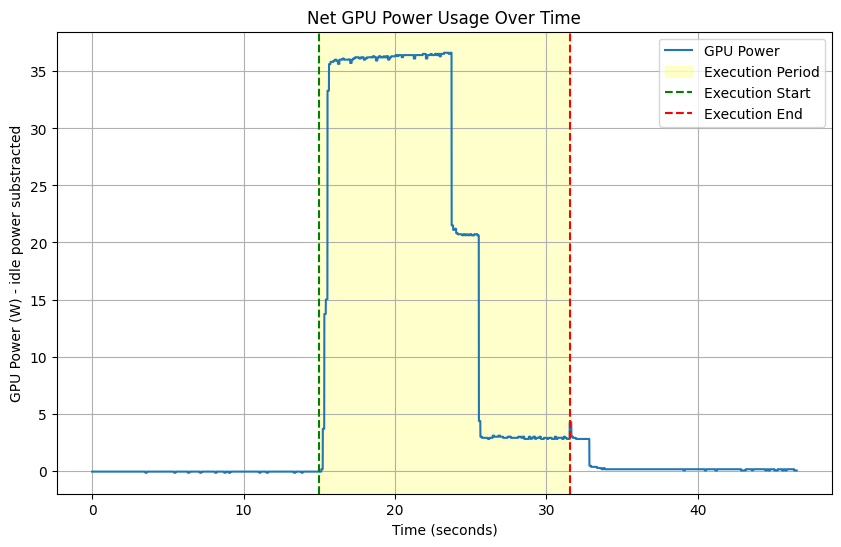

Start time: 15.001 -- End time: 31.538
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0987 Wh
  355.24 J
Average GPU power: 21.49 W +/- 15.56 
 with sample standard deviation.
Net Energy During Exe Runtime:   355.24 J
Code execution duration:  16.54 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 7


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 7 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Core Algorithm**

- Both codes implement the same random number generator (`HPCC_starts`), table initialization (`initTable`), update kernel (`update`), and validation logic.
- The main loop, memory allocation, kernel launches, and validation are all structurally identical.
- The REFACTORED CODE only changes the timing mechanism from C++ `chrono` to CUDA events (`cudaEvent_t`). This does not affect the computation or the results.

### **Kernel Launches**

- Both codes launch `initTable` and `update` kernels with the same grid/block configuration.
- Both codes synchronize after kernel launches before timing and validation.

### **Validation**

- Both codes perform the same validation by applying the same update pattern and checking for errors in the table.

### **Memory Management**

- Both codes allocate and free device and host memory identically.

### **Other Changes**

- The REFACTORED CODE uses CUDA events for timing, which is more energy efficient as it parks the CPU during GPU execution, but does not affect the computation.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844253 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.841082 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### **Analysis**
- The layout and content are nearly identical.
- The only difference is the average kernel execution time, which is expected to differ slightly due to the change in timing method (CUDA events vs. chrono). This is acceptable and reasonable.
- All other printed values and formatting are preserved.

---

## 3. **Metrics**

- The energy and power metrics are nearly identical, with only minor differences (expected due to timing method and measurement noise).
- Execution duration is also nearly identical.

---

## 4. **Conclusion**

- **Functionality:** The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- **Standard Output:** The REFACTORED CODE produces nearly equivalent standard output in both layout and content, with only a minor and reasonable difference in the timing value.

---

**Reasoning:**  
The only change in the REFACTORED CODE is the use of CUDA events for timing, which is a best practice for energy efficiency and does not affect the computation or output. All other aspects of the code are unchanged. The output is nearly identical, and the minor timing difference is justified.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion                                                                 | Pass/Fail |
|---------------------------------------------------------------------------|-----------|
| TableSize is always a power of two, enabling bitmasking                   | Pass      |
| Polynomial-based RNG sequence has correct period and POLY                 | Pass      |
| NUPDATE is computed as 8 * TableSize and divisible by 128                 | Pass      |
| GPU supports 128-thread blocks and atomicXor on 64-bit global memory      | Pass      |
| Host has at least 512 MiB of memory for the update table                  | Pass      |
| TableSize ≥ 1 and remains unchanged throughout kernel launches            | Pass      |
| Each ran[j] is initialized by HPCC_starts and advanced NUPDATE/128 times  | Pass      |
| All accesses to Table use index masked by (TableSize-1)                   | Pass      |
| AtomicXor ensures deterministic updates                                   | Pass      |
| Data-parallel map for initialization                                      | Pass      |
| Data-parallel scatter updates with atomic operations                      | Pass      |
| Use of __restrict__ for pointer aliasing                                  | Pass      |
| Separation of host validation from device computation                     | Pass      |
| initTable: coalesced global writes                                        | Pass      |
| update: pseudo-random scatter writes via atomicXor                        | Pass      |
| ran array: small per-block array accessed in registers                    | Pass      |
| Host allocation: posix_memalign                                           | Pass      |
| Host deallocation: free                                                   | Pass      |
| Device allocation: cudaMalloc for Table and ran                           | Pass      |
| Device deallocation: cudaFree for Table and ran                           | Pass      |
| HPCC_starts uses bit-twinning and polynomial reduction                    | Pass      |
| Loops in HPCC_starts and update are pragma-unrolled                       | Pass      |
| Kernel-launch config: initTable uses ceil(TableSize/256) blocks of 256    | Pass      |
| Kernel-launch config: update uses 1 block of 128 threads                  | Pass      |
| Host timing uses CUDA events                                              | Pass      |
| Host validation replays same XOR sequence and checks error count          | Pass      |


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 352.92
  Refactored code: 355.24
----- Average power (W) -----
  Source code: 21.23
  Refactored code: 21.49
----- Runtime (s) -----
  Source code: 16.63
  Refactored code: 16.54
----- Tracking metrics -----
  Energy (J) history:  [352.92, 352.17, 172.51, 357.0, 353.91, 158.81, 355.01, 355.24]
  Ave Power (W) history:  [21.23, 21.24, 17.32, 21.6, 21.42, 16.22, 21.55, 21.49]
  Runtime (s) history:  [16.63, 16.59, 9.96, 16.53, 16.52, 9.79, 16.47, 16.54]
  Valid code history:  ['SOURCE', 'basellm_stage1_INVALID', 'INVALID', 'VALID', 'VALID', 'INVALID', 'INVALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 

UnboundLocalError: cannot access local variable 'code_comparison_response' where it is not associated with a value

In [6]:
# Experimental repeat for pass@k metrics
trial_number = 1
total_trials = 30

# Load prompt dictionary (to capture recent manual changes to script, if any)
prompts = PromptDictionary()

all_trials_start = time.time()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO REFACTOR
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    input_code_file_subdirectory = "device/cuda/"
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None

while trial_number <= total_trials:
    # CREATE METADATA RECORD CONTENT
    meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
    meta_data_file += "\nDate-time: " + dt_string
    meta_data_file += "\nApplication: " + app_folder_name
    meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
    meta_data_file += "\n\nLLM Source: " + llm_source
    meta_data_file += "\nModel: " + model
    meta_data_file += "\nModel coder: " + model_coder
    meta_data_file += "\nModel judge: " + model_judge
    meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
    meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
    meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
    # meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
    meta_data_file += "\n\nPower measurement: " + str(power_measure)
    
    # Display metadata
    print("\n" + meta_data_file + "\n")
    
    print("\n\n" + color.BLUE + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) *****" + color.END + " Trial #: " + str(trial_number) + "\n\n")
    
    # RUN LASSI-EE PIPELINE
    complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
        prompts,
        this_llm_system_prompt,
        this_llm_refactoredcode_prompt,
        llm_source, 
        model,
        model_coder,
        model_judge,
        num_ctx,
        num_ctx_coder,
        # arrayormatrix_size_range,
        # thread_count_range,
        use_context,
        use_context_summaries_only,
        few_shot_learning,
        input_context,
        input_code_file_subdirectory,
        input_code,
        lines_of_code,
        # target_code,
        target_lang,
        input_code_extension,
        source_lang,
        code_compiler,
        code_compiler_kwds,
        build_script,
        make_script,
        code_build_script,
        output_code_directory,
        output_code_file_name,
        source_file_path,
        display_response,
        test_with_error,
        generate_test_case,
        yes_execute,
        exe_input_parameters,
        meta_data_file,
        power_measure,
        test_code_first,
        yes_power_feedback,
        dt_string,
        baseline_oneshot_goal,
        use_self_prompting,
        vary_llm_temp,
        experiment,
        verifyprompt,
        trial_number,
        experiment_data_directory,
        experiment_data_file_object,
        experiment_data
    )
    
    # Reset to original working directory
    os.chdir(original_home_directory)
    
    if complete:
        print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
    else:
        print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

    # Increment experiment counter
    trial_number = trial_number + 1


all_trials_end = time.time() - all_trials_start

print("\n\n" + color.PURPLE + color.BOLD + "***** ALL TRIALS COMPLETED ***** Total time (min): " + str(round(all_trials_end/60, 2)) + "\n\n" + color.END)